[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JaimeHuaytallaPariona/ingenieria-conocimiento-uncp/blob/master/recursos/sesion_02_modelos_clasificacion.ipynb)

# Sesión 02 — Modelos de Clasificación
**Curso:** Ingeniería del Conocimiento (ISO56B)  
**Docente:** Msc. Jaime Antonio Huaytalla Pariona  
**Periodo:** 2026-II | Universidad Nacional del Centro del Perú  

---

## Objetivo
Implementar, comparar y analizar cuatro modelos fundamentales de clasificación supervisada — **Regresión Logística, Árbol de Decisión, SVM y KNN** — sobre el dataset **Wine Quality** de UCI, evaluando sus fortalezas, limitaciones y sensibilidad al preprocesamiento.

## 1. Configuración del entorno

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay,
    accuracy_score, f1_score
)
from sklearn.inspection import DecisionBoundaryDisplay

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100

RANDOM_STATE = 42
print('Entorno configurado correctamente.')

Entorno configurado correctamente.


---
## 2. Carga y comprensión del dataset

Utilizamos el **Wine Quality (Red)** del repositorio UCI Machine Learning. Contiene 1599 muestras de vino tinto portugués con 11 atributos fisicoquímicos y una puntuación de calidad (3–8).

Para construir un problema de **clasificación binaria**, definimos:
- **Clase 1 (Bueno):** calidad ≥ 7
- **Clase 0 (Estándar):** calidad < 7

Esta binarización genera un **problema desbalanceado**, lo que añade un reto realista al modelado.

In [2]:
# Carga directa desde UCI
URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'

df = pd.read_csv(URL, sep=';')
print(f'Dataset cargado: {df.shape[0]} registros, {df.shape[1]} columnas')
df.head()

Dataset cargado: 1599 registros, 12 columnas


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Distribución de calidad original:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


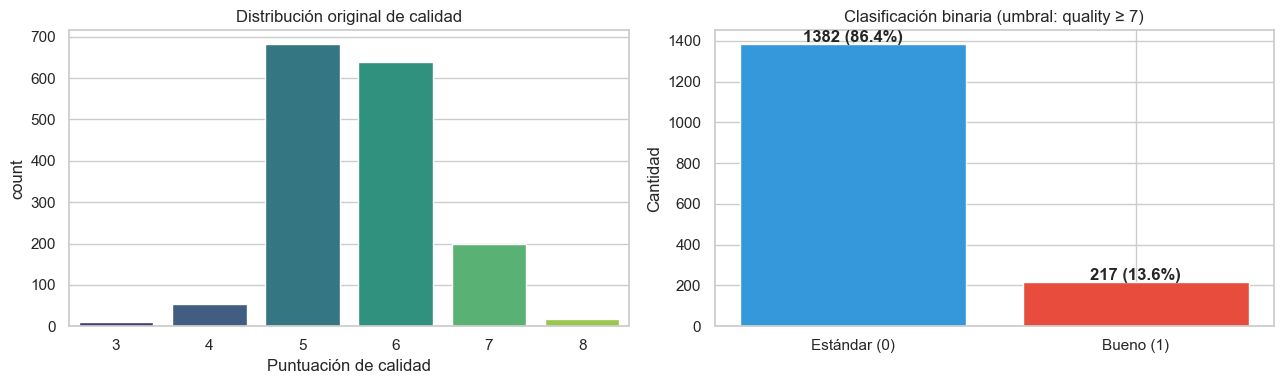


Ratio de desbalance: 6.4:1 (Estándar vs Bueno)


In [3]:
# Distribución original de la variable 'quality'
print('Distribución de calidad original:')
print(df['quality'].value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histograma original
sns.countplot(data=df, x='quality', ax=axes[0], palette='viridis')
axes[0].set_title('Distribución original de calidad')
axes[0].set_xlabel('Puntuación de calidad')

# Binarización
df['quality_label'] = (df['quality'] >= 7).astype(int)

counts = df['quality_label'].value_counts()
axes[1].bar(['Estándar (0)', 'Bueno (1)'], counts.values,
            color=['#3498db', '#e74c3c'])
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 10, f'{v} ({v/len(df)*100:.1f}%)', ha='center', fontweight='bold')
axes[1].set_title('Clasificación binaria (umbral: quality ≥ 7)')
axes[1].set_ylabel('Cantidad')

plt.tight_layout()
plt.show()

print(f'\nRatio de desbalance: {counts[0]/counts[1]:.1f}:1 (Estándar vs Bueno)')

---
## 3. Análisis exploratorio orientado a clasificación

In [4]:
# 3.1  Estadísticas descriptivas por clase
features = df.columns.drop(['quality', 'quality_label'])

comparison = df.groupby('quality_label')[features].mean().T
comparison.columns = ['Estándar (0)', 'Bueno (1)']
comparison['Diferencia %'] = ((comparison['Bueno (1)'] - comparison['Estándar (0)']) / comparison['Estándar (0)'] * 100).round(1)
comparison.style.background_gradient(subset=['Diferencia %'], cmap='RdYlGn')

,Estándar (0),Bueno (1),Diferencia %
fixed acidity,8.236831,8.847005,7.400000
volatile acidity,0.547022,0.405530,-25.900000
citric acid,0.254407,0.376498,48.000000
residual sugar,2.512120,2.708756,7.800000
chlorides,0.089281,0.075912,-15.000000
free sulfur dioxide,16.172214,13.981567,-13.500000
total sulfur dioxide,48.285818,34.889401,-27.700000
density,0.996859,0.996030,-0.100000
pH,3.314616,3.288802,-0.800000
sulphates,0.644754,0.743456,15.300000


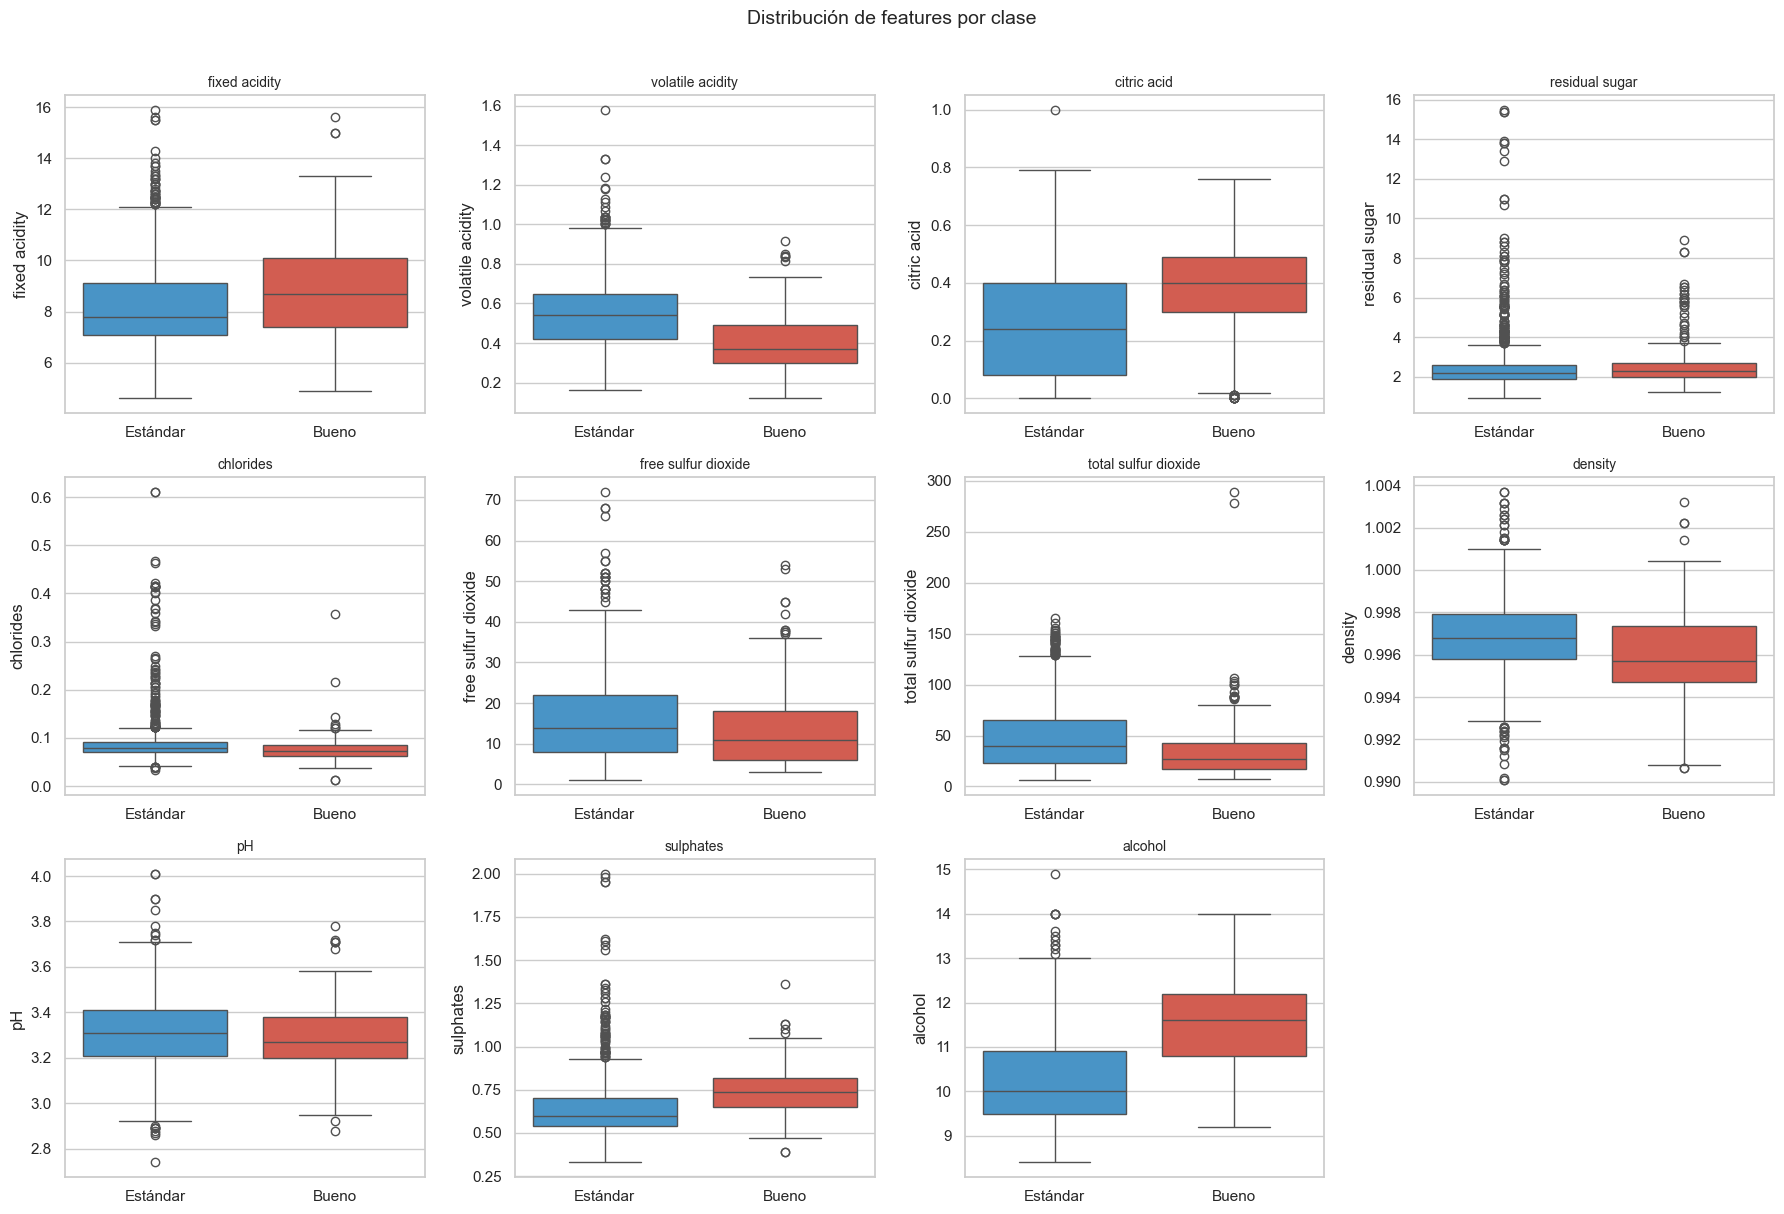

In [5]:
# 3.2  Distribución de features por clase (boxplots)
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(data=df, x='quality_label', y=col, ax=axes[i],
                palette=['#3498db', '#e74c3c'], hue='quality_label', legend=False)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('')
    axes[i].set_xticklabels(['Estándar', 'Bueno'])

# Ocultar subplot vacío
axes[-1].set_visible(False)
fig.suptitle('Distribución de features por clase', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

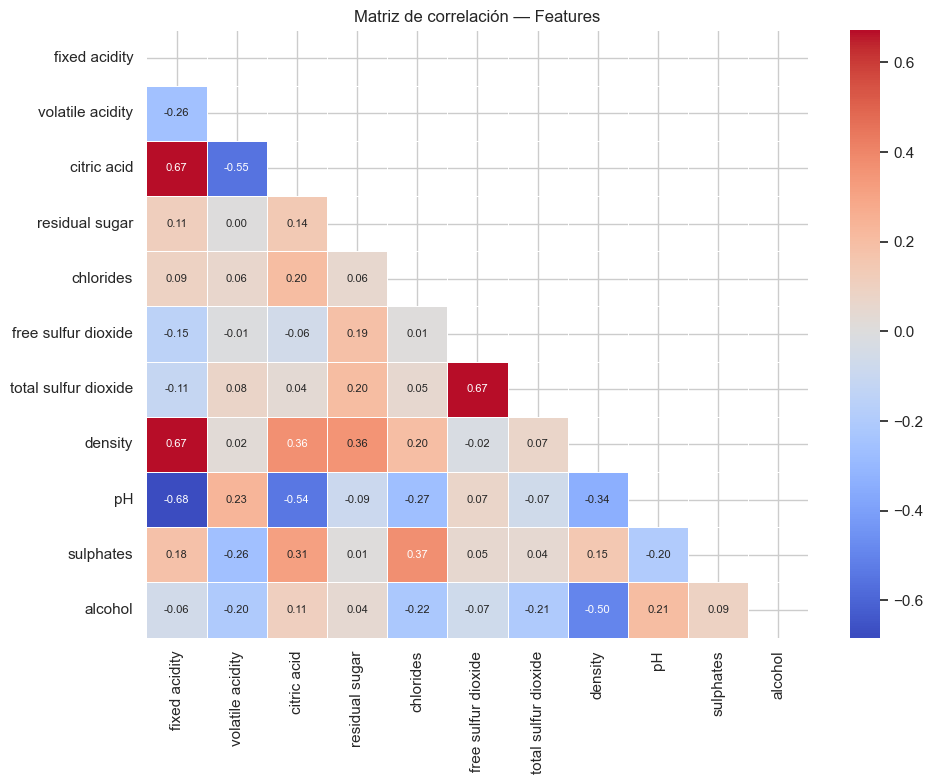

In [6]:
# 3.3  Correlación entre features
plt.figure(figsize=(10, 8))
corr = df[features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, annot_kws={'size': 8})
plt.title('Matriz de correlación — Features')
plt.tight_layout()
plt.show()

---
## 4. Preparación de datos

In [7]:
# 4.1  Separación features / target
X = df[features].copy()
y = df['quality_label'].copy()

# 4.2  Split estratificado 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f'Train: {X_train.shape[0]} muestras  |  Test: {X_test.shape[0]} muestras')
print(f'Proporción clase 1 en train: {y_train.mean():.3f}')
print(f'Proporción clase 1 en test:  {y_test.mean():.3f}')

Train: 1279 muestras  |  Test: 320 muestras
Proporción clase 1 en train: 0.136
Proporción clase 1 en test:  0.134


In [8]:
# 4.3  Verificación de escalas (justifica la estandarización)
print('Rangos de las features (train):')
print('='*50)
for col in features:
    mn, mx = X_train[col].min(), X_train[col].max()
    print(f'{col:30s}  [{mn:8.2f}, {mx:8.2f}]  rango: {mx-mn:.2f}')

print('\n→ Las escalas difieren significativamente entre features.')
print('  Esto afecta directamente a SVM y KNN (basados en distancias).')
print('  Logistic Regression también se beneficia de la estandarización.')

Rangos de las features (train):
fixed acidity                   [    4.60,    15.90]  rango: 11.30
volatile acidity                [    0.12,     1.58]  rango: 1.46
citric acid                     [    0.00,     1.00]  rango: 1.00
residual sugar                  [    0.90,    15.50]  rango: 14.60
chlorides                       [    0.01,     0.61]  rango: 0.60
free sulfur dioxide             [    1.00,    72.00]  rango: 71.00
total sulfur dioxide            [    6.00,   165.00]  rango: 159.00
density                         [    0.99,     1.00]  rango: 0.01
pH                              [    2.74,     4.01]  rango: 1.27
sulphates                       [    0.33,     2.00]  rango: 1.67
alcohol                         [    8.40,    14.90]  rango: 6.50

→ Las escalas difieren significativamente entre features.
  Esto afecta directamente a SVM y KNN (basados en distancias).
  Logistic Regression también se beneficia de la estandarización.


---
## 5. Modelo 1 — Regresión Logística

**Fundamento:** Modelo lineal que estima la probabilidad de pertenencia a una clase mediante la función sigmoide. Ideal como **baseline** por su interpretabilidad y eficiencia.

In [9]:
# 5.1  Pipeline con estandarización
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                               class_weight='balanced'))  # Compensar desbalance
])

# Validación cruzada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores_lr = cross_val_score(pipe_lr, X_train, y_train, cv=cv, scoring='f1')
print(f'Logistic Regression — F1 CV: {scores_lr.mean():.4f} ± {scores_lr.std():.4f}')

# Entrenamiento final
pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)

Logistic Regression — F1 CV: 0.5045 ± 0.0355


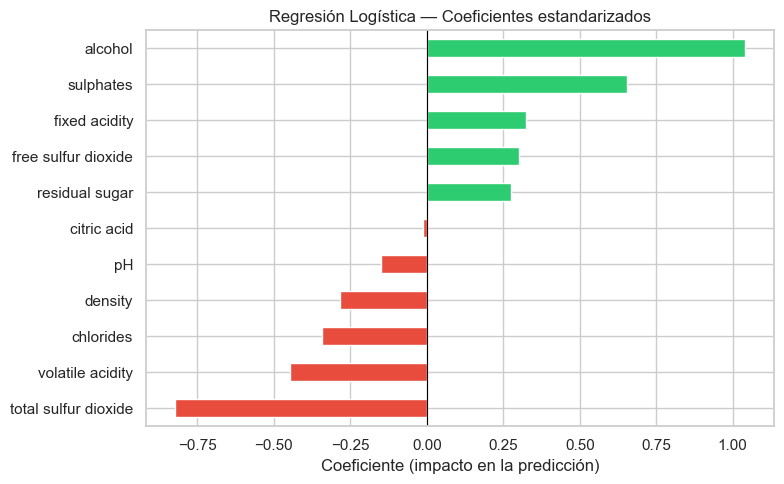


Interpretación: Un coeficiente positivo alto indica que valores mayores
de esa feature incrementan la probabilidad de clasificar como "Bueno".


In [10]:
# 5.2  Coeficientes del modelo (interpretabilidad)
coefs = pd.Series(
    pipe_lr.named_steps['clf'].coef_[0],
    index=features
).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#e74c3c' if c < 0 else '#2ecc71' for c in coefs.values]
coefs.plot(kind='barh', ax=ax, color=colors)
ax.set_title('Regresión Logística — Coeficientes estandarizados')
ax.set_xlabel('Coeficiente (impacto en la predicción)')
ax.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

print('\nInterpretación: Un coeficiente positivo alto indica que valores mayores')
print('de esa feature incrementan la probabilidad de clasificar como "Bueno".')

---
## 6. Modelo 2 — Árbol de Decisión

**Fundamento:** Modelo no lineal que particiona el espacio de features mediante reglas if-else jerárquicas. Altamente interpretable, pero propenso al sobreajuste si no se controla la profundidad.

In [11]:
# 6.1  Pipeline (no requiere estandarización)
pipe_dt = Pipeline([
    ('clf', DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=10,
        class_weight='balanced', random_state=RANDOM_STATE
    ))
])

scores_dt = cross_val_score(pipe_dt, X_train, y_train, cv=cv, scoring='f1')
print(f'Decision Tree — F1 CV: {scores_dt.mean():.4f} ± {scores_dt.std():.4f}')

pipe_dt.fit(X_train, y_train)
y_pred_dt = pipe_dt.predict(X_test)

Decision Tree — F1 CV: 0.5126 ± 0.0331


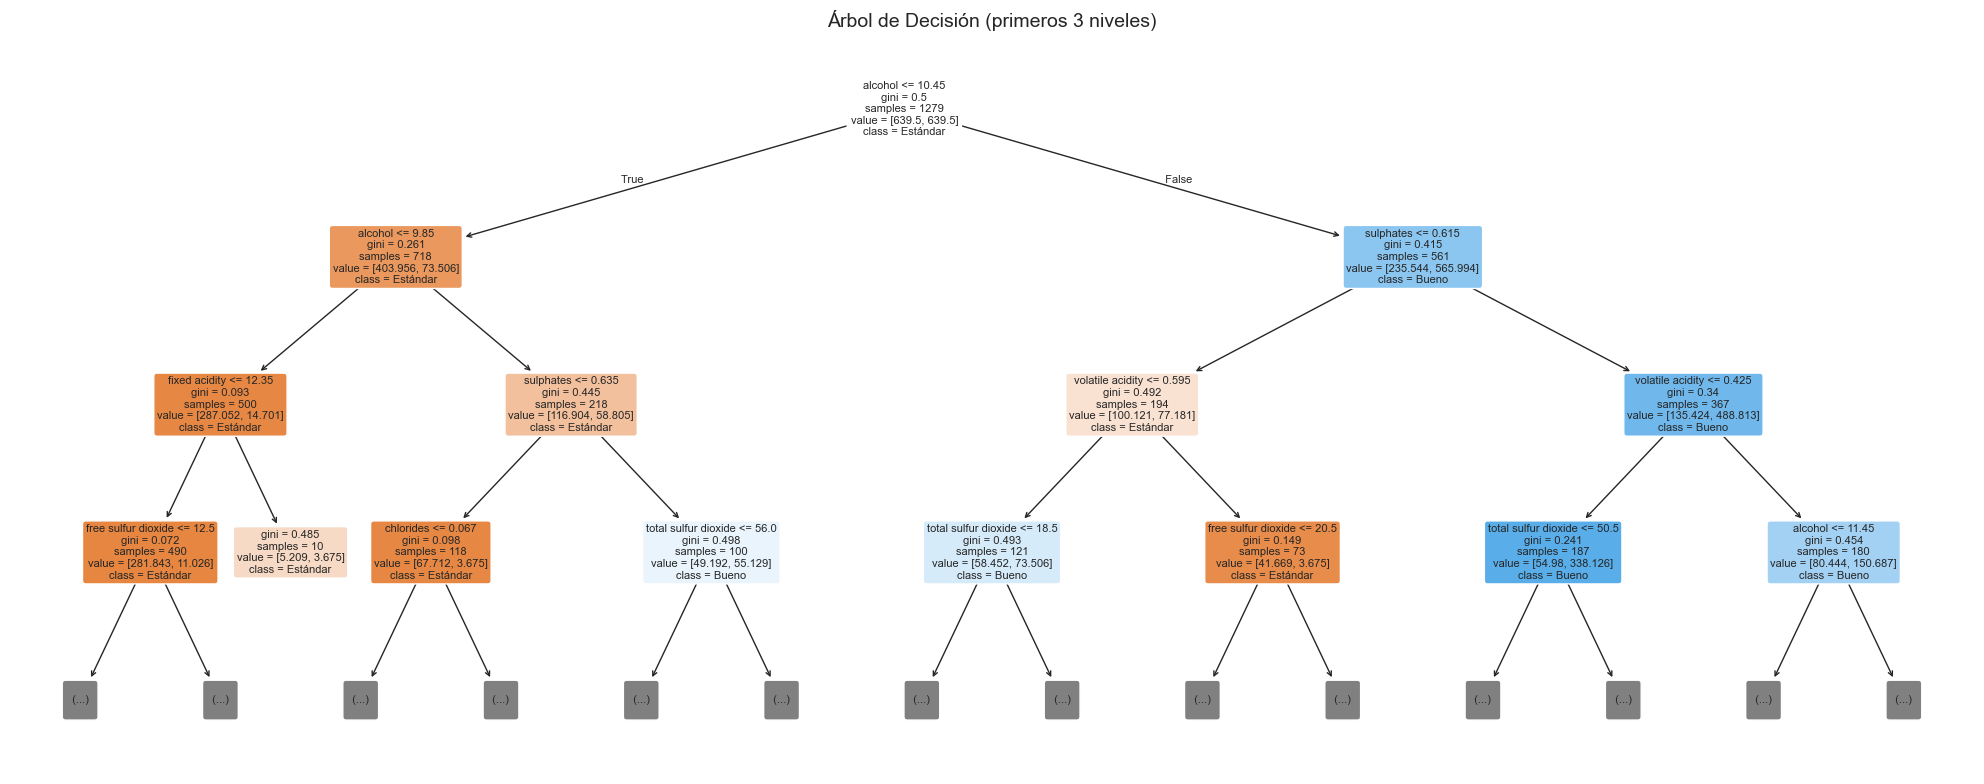

In [12]:
# 6.2  Visualización del árbol
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(
    pipe_dt.named_steps['clf'],
    feature_names=list(features),
    class_names=['Estándar', 'Bueno'],
    filled=True, rounded=True, fontsize=8, ax=ax,
    max_depth=3  # Mostrar solo 3 niveles para legibilidad
)
ax.set_title('Árbol de Decisión (primeros 3 niveles)', fontsize=14)
plt.tight_layout()
plt.show()

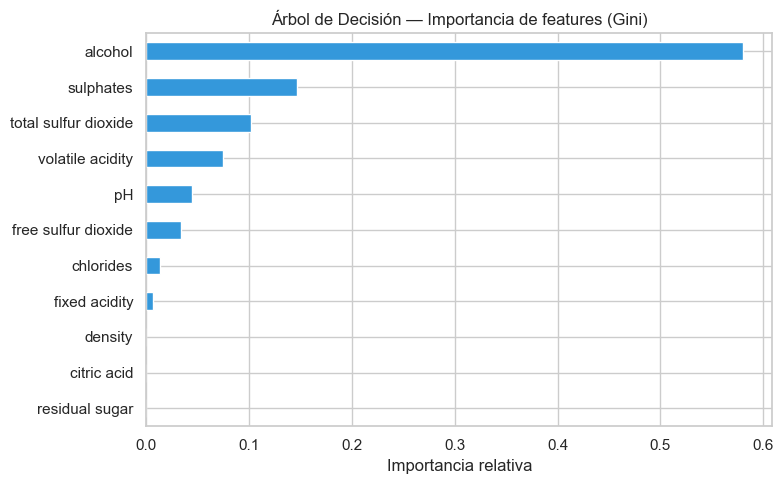

In [13]:
# 6.3  Importancia de features (Gini importance)
importances = pd.Series(
    pipe_dt.named_steps['clf'].feature_importances_,
    index=features
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind='barh', ax=ax, color='#3498db')
ax.set_title('Árbol de Decisión — Importancia de features (Gini)')
ax.set_xlabel('Importancia relativa')
plt.tight_layout()
plt.show()

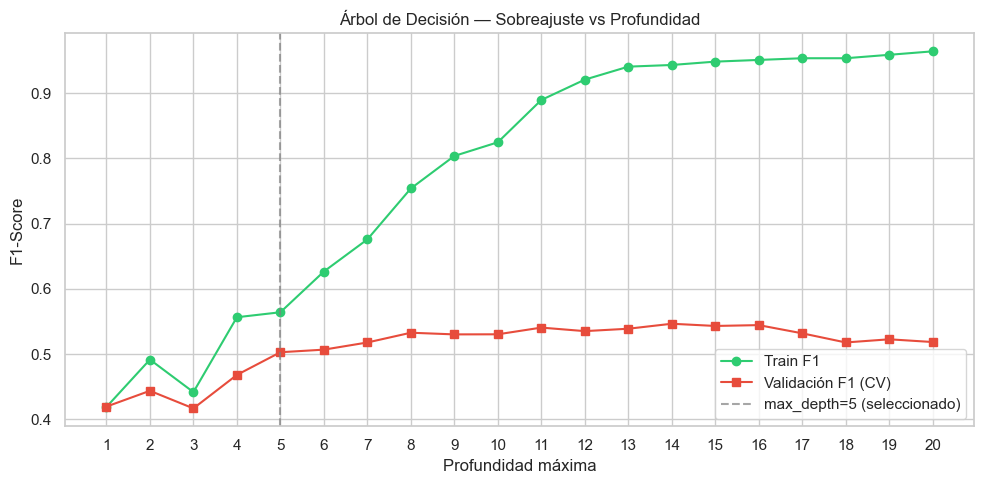

Observación: cuando la brecha entre train y validación crece,
el modelo está sobreajustando (memorizando el train set).


In [14]:
# 6.4  Efecto de la profundidad en sobreajuste/subajuste
depths = range(1, 21)
train_scores = []
val_scores = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, class_weight='balanced',
                                 random_state=RANDOM_STATE)
    dt.fit(X_train, y_train)
    train_scores.append(f1_score(y_train, dt.predict(X_train)))
    cv_s = cross_val_score(dt, X_train, y_train, cv=cv, scoring='f1')
    val_scores.append(cv_s.mean())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depths, train_scores, 'o-', label='Train F1', color='#2ecc71')
ax.plot(depths, val_scores, 's-', label='Validación F1 (CV)', color='#e74c3c')
ax.axvline(x=5, color='gray', linestyle='--', alpha=0.7, label='max_depth=5 (seleccionado)')
ax.set_xlabel('Profundidad máxima')
ax.set_ylabel('F1-Score')
ax.set_title('Árbol de Decisión — Sobreajuste vs Profundidad')
ax.legend()
ax.set_xticks(depths)
plt.tight_layout()
plt.show()

print('Observación: cuando la brecha entre train y validación crece,')
print('el modelo está sobreajustando (memorizando el train set).')

---
## 7. Modelo 3 — Support Vector Machine (SVM)

**Fundamento:** Busca el hiperplano que maximiza el margen de separación entre clases. Con funciones kernel puede manejar fronteras no lineales. Es **sensible a la escala** de las features.

In [15]:
# 7.1  Comparación de kernels
kernels = ['linear', 'rbf', 'poly']
svm_results = {}

for kernel in kernels:
    pipe_svm = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel=kernel, class_weight='balanced',
                     random_state=RANDOM_STATE, probability=True))
    ])
    scores = cross_val_score(pipe_svm, X_train, y_train, cv=cv, scoring='f1')
    svm_results[kernel] = scores
    print(f'SVM ({kernel:6s}) — F1 CV: {scores.mean():.4f} ± {scores.std():.4f}')

# Seleccionar el mejor kernel
best_kernel = max(svm_results, key=lambda k: svm_results[k].mean())
print(f'\nMejor kernel: {best_kernel}')

SVM (linear) — F1 CV: 0.4982 ± 0.0237
SVM (rbf   ) — F1 CV: 0.5246 ± 0.0427
SVM (poly  ) — F1 CV: 0.5355 ± 0.0258

Mejor kernel: poly


In [16]:
# 7.2  Entrenamiento con el mejor kernel
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel=best_kernel, class_weight='balanced',
                 random_state=RANDOM_STATE, probability=True))
])

pipe_svm.fit(X_train, y_train)
y_pred_svm = pipe_svm.predict(X_test)
scores_svm = svm_results[best_kernel]

In [17]:
# 7.3  Impacto de la estandarización en SVM
# SVM SIN estandarizar
svm_no_scale = SVC(kernel=best_kernel, class_weight='balanced',
                    random_state=RANDOM_STATE)
scores_no_scale = cross_val_score(svm_no_scale, X_train, y_train, cv=cv, scoring='f1')

print('Impacto de la estandarización en SVM:')
print(f'  CON StandardScaler: F1 = {scores_svm.mean():.4f}')
print(f'  SIN StandardScaler: F1 = {scores_no_scale.mean():.4f}')
print(f'  Diferencia: {(scores_svm.mean() - scores_no_scale.mean())*100:+.2f} puntos porcentuales')
print('\n→ La estandarización es CRÍTICA para modelos basados en distancias.')

Impacto de la estandarización en SVM:
  CON StandardScaler: F1 = 0.5355
  SIN StandardScaler: F1 = 0.2832
  Diferencia: +25.23 puntos porcentuales

→ La estandarización es CRÍTICA para modelos basados en distancias.


---
## 8. Modelo 4 — K-Nearest Neighbors (KNN)

**Fundamento:** Clasifica según la mayoría de votos de los K vecinos más cercanos. No paramétrico, sensible a la escala y a la dimensionalidad. El valor de K controla el trade-off bias-varianza.

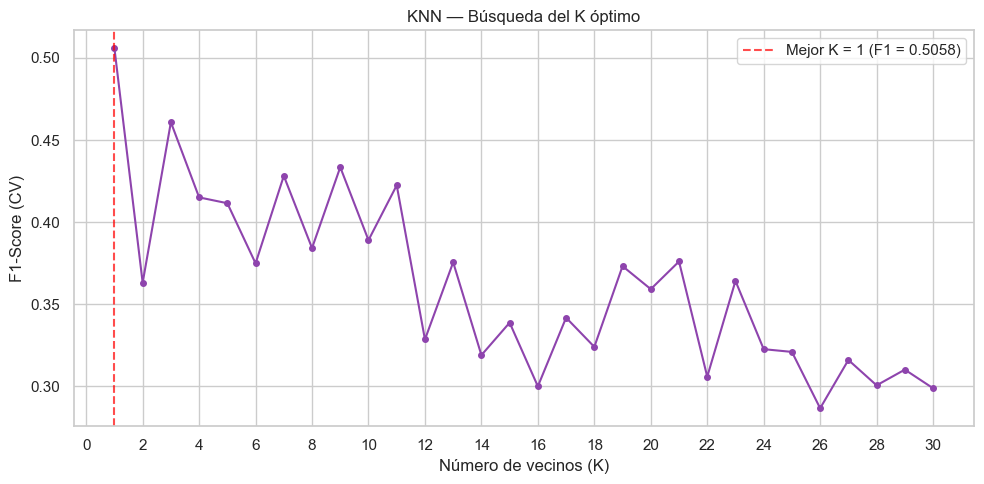

K óptimo: 1


In [18]:
# 8.1  Búsqueda del K óptimo
k_range = range(1, 31)
k_scores = []

for k in k_range:
    pipe_knn = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(pipe_knn, X_train, y_train, cv=cv, scoring='f1')
    k_scores.append(scores.mean())

best_k = k_range[np.argmax(k_scores)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_range, k_scores, 'o-', markersize=4, color='#8e44ad')
ax.axvline(x=best_k, color='red', linestyle='--', alpha=0.7,
           label=f'Mejor K = {best_k} (F1 = {max(k_scores):.4f})')
ax.set_xlabel('Número de vecinos (K)')
ax.set_ylabel('F1-Score (CV)')
ax.set_title('KNN — Búsqueda del K óptimo')
ax.legend()
ax.set_xticks(range(0, 31, 2))
plt.tight_layout()
plt.show()

print(f'K óptimo: {best_k}')

In [19]:
# 8.2  Entrenamiento con K óptimo
pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', KNeighborsClassifier(n_neighbors=best_k))
])

scores_knn = cross_val_score(pipe_knn, X_train, y_train, cv=cv, scoring='f1')
print(f'KNN (K={best_k}) — F1 CV: {scores_knn.mean():.4f} ± {scores_knn.std():.4f}')

pipe_knn.fit(X_train, y_train)
y_pred_knn = pipe_knn.predict(X_test)

KNN (K=1) — F1 CV: 0.5058 ± 0.0254


---
## 9. Análisis comparativo de modelos

In [20]:
# 9.1  Tabla resumen
models = {
    'Logistic Regression': (pipe_lr, y_pred_lr, scores_lr),
    'Decision Tree':       (pipe_dt, y_pred_dt, scores_dt),
    f'SVM ({best_kernel})': (pipe_svm, y_pred_svm, scores_svm),
    f'KNN (K={best_k})':   (pipe_knn, y_pred_knn, scores_knn)
}

summary = []
for name, (pipe, y_pred, cv_scores) in models.items():
    summary.append({
        'Modelo': name,
        'F1 CV (mean)': f'{cv_scores.mean():.4f}',
        'F1 CV (std)': f'{cv_scores.std():.4f}',
        'Accuracy Test': f'{accuracy_score(y_test, y_pred):.4f}',
        'F1 Test': f'{f1_score(y_test, y_pred):.4f}'
    })

summary_df = pd.DataFrame(summary)
print('='*80)
print('COMPARACIÓN DE MODELOS')
print('='*80)
summary_df

COMPARACIÓN DE MODELOS


,Modelo,F1 CV (mean),F1 CV (std),Accuracy Test,F1 Test
0,Logistic Regression,0.5045,0.0355,0.8125,0.5312
1,Decision Tree,0.5126,0.0331,0.8094,0.5414
2,SVM (poly),0.5355,0.0258,0.8969,0.6598
3,KNN (K=1),0.5058,0.0254,0.9094,0.6588


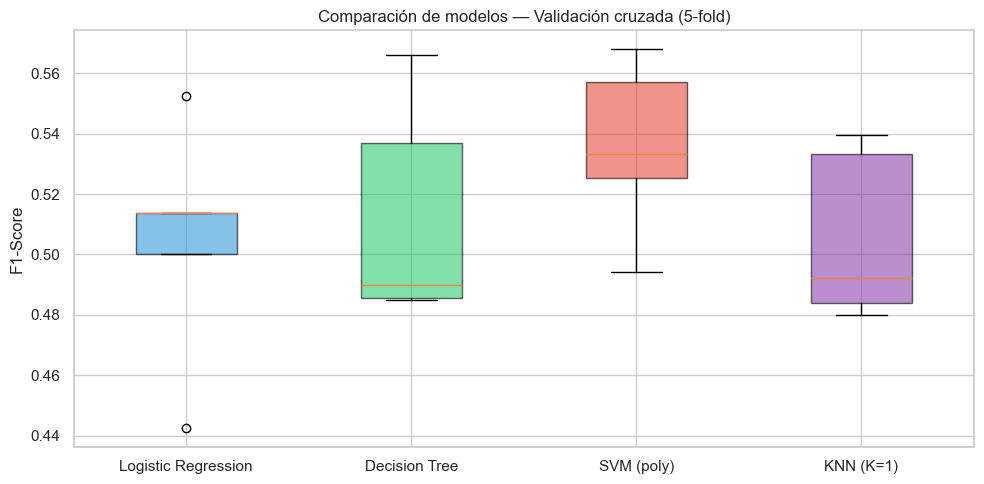

In [21]:
# 9.2  Boxplot comparativo de validación cruzada
fig, ax = plt.subplots(figsize=(10, 5))
cv_data = [scores_lr, scores_dt, scores_svm, scores_knn]
labels = list(models.keys())
bp = ax.boxplot(cv_data, tick_labels=labels, patch_artist=True)
colors_box = ['#3498db', '#2ecc71', '#e74c3c', '#8e44ad']
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
ax.set_ylabel('F1-Score')
ax.set_title('Comparación de modelos — Validación cruzada (5-fold)')
plt.tight_layout()
plt.show()

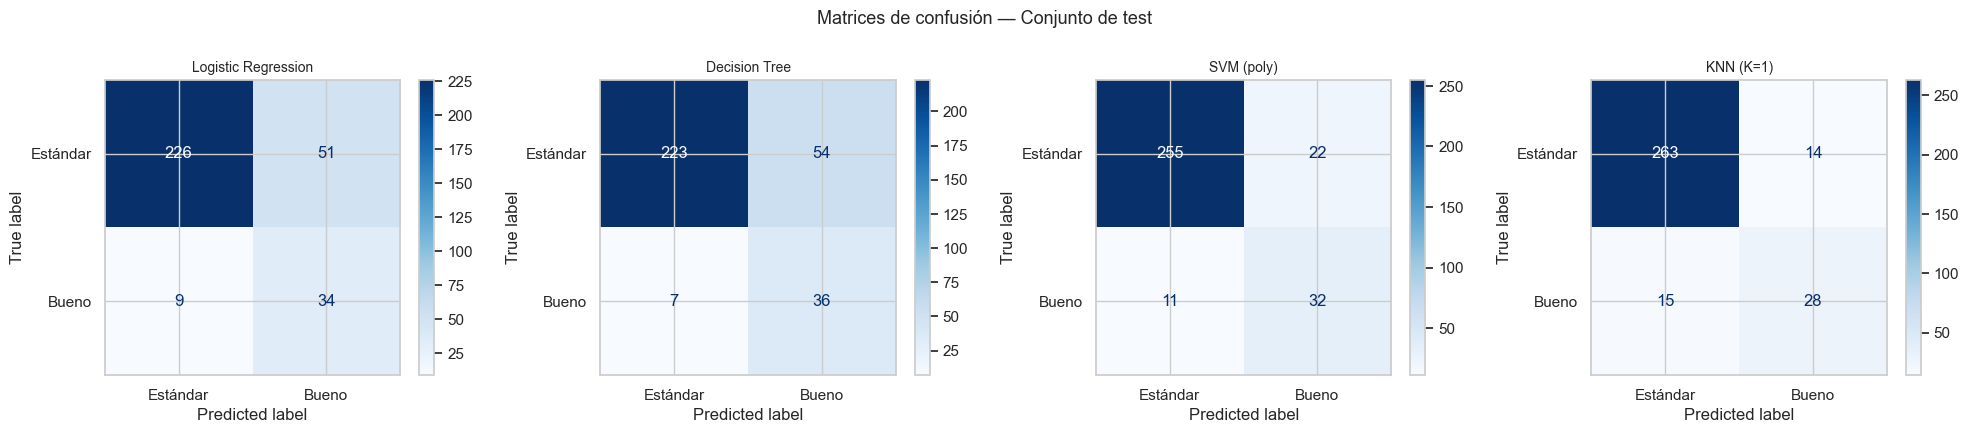

In [22]:
# 9.3  Matrices de confusión comparativas
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, (name, (pipe, y_pred, _)) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=['Estándar', 'Bueno'],
        cmap='Blues', ax=ax
    )
    ax.set_title(name, fontsize=10)

fig.suptitle('Matrices de confusión — Conjunto de test', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

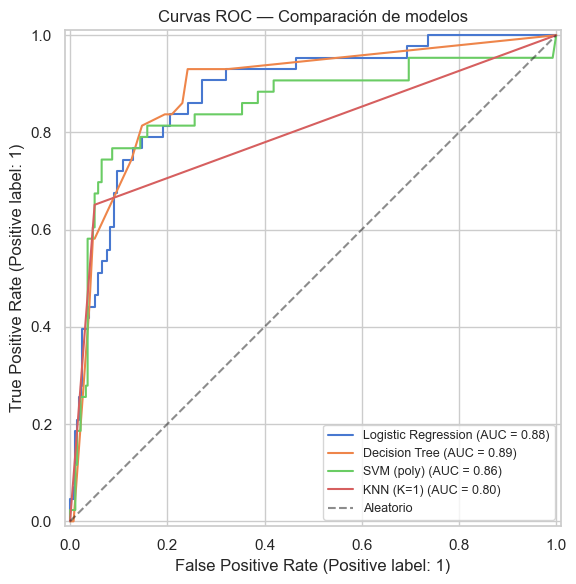

In [23]:
# 9.4  Curvas ROC comparativas
fig, ax = plt.subplots(figsize=(7, 6))

for name, (pipe, _, _) in models.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=ax, name=name)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aleatorio')
ax.set_title('Curvas ROC — Comparación de modelos')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

In [24]:
# 9.5  Classification report detallado del mejor modelo
best_model_name = max(models, key=lambda k: float(models[k][2].mean()))
best_pipe, best_pred, best_cv = models[best_model_name]

print(f'\nMejor modelo: {best_model_name}')
print('='*60)
print(classification_report(y_test, best_pred,
                             target_names=['Estándar', 'Bueno']))


Mejor modelo: SVM (poly)
              precision    recall  f1-score   support

    Estándar       0.96      0.92      0.94       277
       Bueno       0.59      0.74      0.66        43

    accuracy                           0.90       320
   macro avg       0.78      0.83      0.80       320
weighted avg       0.91      0.90      0.90       320



---
## 10. Resumen comparativo

| Modelo | Fortalezas | Limitaciones | ¿Cuándo usarlo? |
|---|---|---|---|
| **Regresión Logística** | Rápido, interpretable (coeficientes), probabilístico | Asume relación lineal entre features y log-odds | Baseline; cuando la interpretabilidad es prioritaria |
| **Árbol de Decisión** | Interpretable (visualización), maneja no linealidades, no requiere estandarización | Propenso a sobreajuste; inestable (pequeños cambios en datos alteran el árbol) | Cuando se necesitan reglas explicables; como parte de ensambles |
| **SVM** | Efectivo en alta dimensionalidad; flexible con kernels | Sensible a la escala; costoso en datasets grandes; difícil de interpretar | Datasets de tamaño moderado con fronteras complejas |
| **KNN** | Simple, no paramétrico, adaptable | Lento en predicción (distancias contra todo el train); sensible a escala y dimensionalidad | Datasets pequeños-medianos; cuando la frontera es irregular |

---
## 11. Ejercicios propuestos

### Ejercicio 1 — GridSearchCV para SVM
Realice una búsqueda de hiperparámetros para SVM usando `GridSearchCV` con la siguiente grilla:
- `C`: [0.1, 1, 10, 100]
- `gamma`: ['scale', 'auto', 0.01, 0.1]
- `kernel`: ['rbf', 'poly']

Reporte los mejores hiperparámetros, el F1-score obtenido y compare contra el SVM base de la sesión.

### Ejercicio 2 — Clasificación multiclase
En lugar de binarizar la variable `quality`, utilice las clases originales (3–8) y entrene los 4 modelos. Analice:
- ¿Cómo cambia el rendimiento de cada modelo?
- ¿Qué clases son más difíciles de distinguir?
- ¿Qué métrica de F1 es más adecuada: `macro`, `micro` o `weighted`? Justifique.

### Ejercicio 3 — Aplicación con dataset propio
Seleccione un dataset de clasificación de su interés (puede ser de Kaggle, UCI, o datos propios). Debe tener al menos 500 registros y 5 features. Aplique los 4 modelos de clasificación, realice el análisis comparativo completo y documente sus hallazgos.

---
*Ingeniería del Conocimiento (ISO56B) — UNCP — 2026-II*

---
## 12. Ejercicio 1 — Solución: GridSearchCV para SVM

**Objetivo:** Encontrar la mejor combinación de hiperparámetros para SVM
mediante búsqueda exhaustiva con validación cruzada.

**Grilla:**
- `C`: [0.1, 1, 10, 100]
- `gamma`: ['scale', 'auto', 0.01, 0.1]
- `kernel`: ['rbf', 'poly']

**Total:** 4 × 4 × 2 = 32 combinaciones × 5 folds = 160 entrenamientos.

In [25]:
# Verificar que los objetos de la sesión base están cargados
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape, "| positivos:", y_train.sum())
print("y_test: ", y_test.shape,  "| positivos:", y_test.sum())
print("best_kernel base:", best_kernel)
print(f"SVM base ({best_kernel}) F1 CV:   {scores_svm.mean():.4f}")

X_train: (1279, 11)
X_test:  (320, 11)
y_train: (1279,) | positivos: 174
y_test:  (320,) | positivos: 43
best_kernel base: poly
SVM base (poly) F1 CV:   0.5355


In [26]:
from sklearn.model_selection import GridSearchCV
import time

# Pipeline "limpio" (sin kernel fijo, lo decide GridSearch)
pipe_svm_gs = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(class_weight='balanced', probability=False,
                random_state=RANDOM_STATE))
])

# Grilla de hiperparámetros
param_grid = {
    'clf__C':      [0.1, 1, 10, 100],
    'clf__gamma':  ['scale', 'auto', 0.01, 0.1],
    'clf__kernel': ['rbf', 'poly']
}

# Instanciar GridSearchCV
grid_svm = GridSearchCV(
    estimator=pipe_svm_gs,
    param_grid=param_grid,
    cv=cv,                  # StratifiedKFold de la sesión base
    scoring='f1',           # misma métrica que usamos antes
    n_jobs=-1,              # paralelizar en todos los núcleos
    verbose=1,
    return_train_score=True
)

n_combos = (len(param_grid['clf__C']) *
            len(param_grid['clf__gamma']) *
            len(param_grid['clf__kernel']))
print(f"Combinaciones:        {n_combos}")
print(f"Entrenamientos totales: {n_combos * 5}")

Combinaciones:        32
Entrenamientos totales: 160


In [27]:
t0 = time.time()
grid_svm.fit(X_train, y_train)
t_total = time.time() - t0

print(f"\n⏱️  Tiempo total: {t_total:.1f} s ({t_total/60:.1f} min)")

Fitting 5 folds for each of 32 candidates, totalling 160 fits

⏱️  Tiempo total: 21.4 s (0.4 min)


In [28]:
print("=" * 60)
print("RESULTADO DE GridSearchCV")
print("=" * 60)
print(f"Mejores hiperparámetros: {grid_svm.best_params_}")
print(f"Mejor F1 (CV 5-fold):    {grid_svm.best_score_:.4f}")
print()
print(f"SVM base ({best_kernel}) F1 CV:   {scores_svm.mean():.4f}")
mejora = (grid_svm.best_score_ - scores_svm.mean()) * 100
print(f"Mejora con GridSearch:   {mejora:+.2f} puntos porcentuales")

RESULTADO DE GridSearchCV
Mejores hiperparámetros: {'clf__C': 10, 'clf__gamma': 0.1, 'clf__kernel': 'rbf'}
Mejor F1 (CV 5-fold):    0.5450

SVM base (poly) F1 CV:   0.5355
Mejora con GridSearch:   +0.95 puntos porcentuales


In [29]:
cvres = pd.DataFrame(grid_svm.cv_results_)

cols = ['param_clf__kernel', 'param_clf__C', 'param_clf__gamma',
        'mean_test_score', 'std_test_score',
        'mean_train_score', 'rank_test_score']

tabla = cvres[cols].sort_values('rank_test_score').round(4)
print("Top 10 combinaciones (por rank):")
tabla.head(10)

Top 10 combinaciones (por rank):


,param_clf__kernel,param_clf__C,param_clf__gamma,mean_test_score,std_test_score,mean_train_score,rank_test_score
22,rbf,10.0,0.1,0.5450,0.0413,0.7848,1
7,poly,0.1,0.1,0.5406,0.0445,0.5848,2
29,poly,100.0,0.01,0.5406,0.0445,0.5848,2
9,poly,1.0,scale,0.5355,0.0258,0.6545,4
11,poly,1.0,auto,0.5355,0.0258,0.6545,4
18,rbf,10.0,auto,0.5343,0.0397,0.7688,6
16,rbf,10.0,scale,0.5343,0.0397,0.7688,6
23,poly,10.0,0.1,0.5313,0.0239,0.7378,8
15,poly,1.0,0.1,0.5288,0.0296,0.6641,9
3,poly,0.1,auto,0.5279,0.0448,0.5817,10


In [30]:
best_pipe_svm = grid_svm.best_estimator_
y_pred_svm_gs = best_pipe_svm.predict(X_test)

print("=" * 60)
print("EVALUACIÓN EN TEST — SVM optimizado")
print("=" * 60)
print(f"Accuracy: {accuracy_score(y_test, y_pred_svm_gs):.4f}")
print(f"F1:       {f1_score(y_test, y_pred_svm_gs):.4f}")
print()
print(classification_report(y_test, y_pred_svm_gs,
                             target_names=['Estándar', 'Bueno']))

EVALUACIÓN EN TEST — SVM optimizado
Accuracy: 0.8781
F1:       0.6422

              precision    recall  f1-score   support

    Estándar       0.97      0.89      0.93       277
       Bueno       0.53      0.81      0.64        43

    accuracy                           0.88       320
   macro avg       0.75      0.85      0.78       320
weighted avg       0.91      0.88      0.89       320



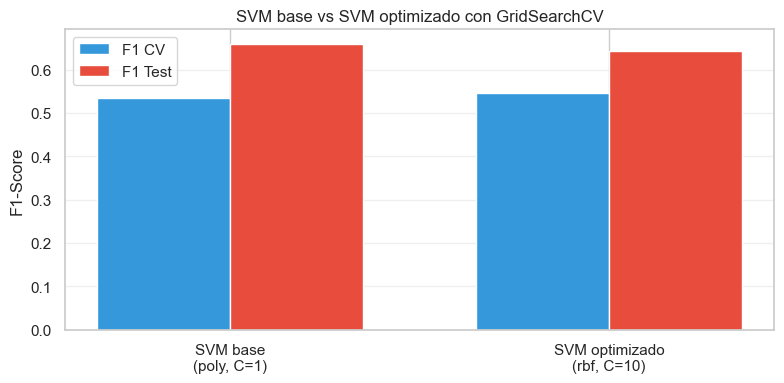

In [31]:
# Comparación gráfica: SVM base vs SVM optimizado
fig, ax = plt.subplots(figsize=(8, 4))

modelos = [f'SVM base\n({best_kernel}, C=1)',
           f'SVM optimizado\n({grid_svm.best_params_["clf__kernel"]}, '
           f'C={grid_svm.best_params_["clf__C"]})']
f1_cv  = [scores_svm.mean(), grid_svm.best_score_]
f1_te  = [f1_score(y_test, y_pred_svm), f1_score(y_test, y_pred_svm_gs)]

x = np.arange(len(modelos))
w = 0.35
ax.bar(x - w/2, f1_cv, w, label='F1 CV',   color='#3498db')
ax.bar(x + w/2, f1_te, w, label='F1 Test', color='#e74c3c')
ax.set_xticks(x)
ax.set_xticklabels(modelos)
ax.set_ylabel('F1-Score')
ax.set_title('SVM base vs SVM optimizado con GridSearchCV')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

---
## 13. Ejercicio 2 — Clasificación Multiclase

**Objetivo:** Entrenar los 4 modelos usando las clases originales de calidad
(3, 4, 5, 6, 7, 8) en lugar de la binarización.

**Preguntas:**
1. ¿Cómo cambia el rendimiento?
2. ¿Qué clases son más difíciles de distinguir?
3. ¿Qué F1 usar: macro, micro o weighted?

In [32]:
# ============================================================
# PREPARACIÓN DEL TARGET MULTICLASE
# ============================================================

# Usamos la variable 'quality' original (3-8), NO 'quality_label' (binarizada)
y_multi = df['quality'].copy()

print("Distribución de clases originales:")
print(y_multi.value_counts().sort_index())
print()
print(f"Clases únicas: {sorted(y_multi.unique())}")
print(f"Número de clases: {y_multi.nunique()}")
print(f"Total muestras: {len(y_multi)}")

Distribución de clases originales:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Clases únicas: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Número de clases: 6
Total muestras: 1599


In [33]:
# Split estratificado para multiclase
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X, y_multi,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_multi   # respeta proporciones de las 6 clases
)

print(f"Train: {X_train_m.shape[0]} muestras")
print(f"Test:  {X_test_m.shape[0]} muestras")
print()
print("Distribución en train (verificar estratificación):")
print(y_train_m.value_counts().sort_index())
print()
print("Distribución en test:")
print(y_test_m.value_counts().sort_index())

# CV estratificado para multiclase
cv_multi = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: 1279 muestras
Test:  320 muestras

Distribución en train (verificar estratificación):
quality
3      8
4     42
5    545
6    510
7    159
8     15
Name: count, dtype: int64

Distribución en test:
quality
3      2
4     11
5    136
6    128
7     40
8      3
Name: count, dtype: int64


In [34]:
# ============================================================
# ENTRENAMIENTO DE LOS 4 MODELOS EN MULTICLASE
# ============================================================

modelos_multi = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=2000,
                                    class_weight='balanced',
                                    random_state=RANDOM_STATE))
    ]),
    'Decision Tree': Pipeline([
        ('clf', DecisionTreeClassifier(max_depth=5, min_samples_leaf=10,
                                        class_weight='balanced',
                                        random_state=RANDOM_STATE))
    ]),
    'SVM (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', class_weight='balanced',
                    probability=True, random_state=RANDOM_STATE))
    ]),
    'KNN (K=5)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ])
}

# Validación cruzada con F1-MACRO (clave: es multiclase)
print("Resultados CV 5-fold (F1-MACRO):")
print("=" * 60)
cv_multi_results = {}

for nombre, pipe in modelos_multi.items():
    scores = cross_val_score(pipe, X_train_m, y_train_m,
                             cv=cv_multi, scoring='f1_macro')
    cv_multi_results[nombre] = scores
    print(f"  {nombre:22s}: {scores.mean():.4f} ± {scores.std():.4f}")

# Entrenar cada modelo en todo el train
for nombre, pipe in modelos_multi.items():
    pipe.fit(X_train_m, y_train_m)

Resultados CV 5-fold (F1-MACRO):
  Logistic Regression   : 0.2841 ± 0.0167
  Decision Tree         : 0.2224 ± 0.0207
  SVM (RBF)             : 0.2872 ± 0.0251
  KNN (K=5)             : 0.2894 ± 0.0147


In [35]:
# ============================================================
# EVALUACIÓN EN TEST
# ============================================================

print("=" * 70)
print("MÉTRICAS EN TEST — CLASIFICACIÓN MULTICLASE")
print("=" * 70)

resultados_multi = {}

for nombre, pipe in modelos_multi.items():
    y_pred = pipe.predict(X_test_m)
    resultados_multi[nombre] = {
        'Accuracy':    accuracy_score(y_test_m, y_pred),
        'F1-macro':    f1_score(y_test_m, y_pred, average='macro'),
        'F1-weighted': f1_score(y_test_m, y_pred, average='weighted'),
    }

df_res = pd.DataFrame(resultados_multi).T.round(4)
print(df_res)

MÉTRICAS EN TEST — CLASIFICACIÓN MULTICLASE
                     Accuracy  F1-macro  F1-weighted
Logistic Regression    0.3969    0.2402       0.4408
Decision Tree          0.3969    0.2702       0.4089
SVM (RBF)              0.4594    0.2754       0.4918
KNN (K=5)              0.6094    0.3107       0.5959


In [36]:
# ============================================================
# REPORTE DETALLADO DEL MEJOR MODELO (por F1-macro)
# ============================================================

mejor_multi = max(resultados_multi, key=lambda k: resultados_multi[k]['F1-macro'])
mejor_pipe_multi = modelos_multi[mejor_multi]
y_pred_best = mejor_pipe_multi.predict(X_test_m)

print(f"Mejor modelo: {mejor_multi}")
print("=" * 60)
print(classification_report(y_test_m, y_pred_best))

Mejor modelo: KNN (K=5)
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.65      0.68      0.66       136
           6       0.57      0.62      0.59       128
           7       0.64      0.57      0.61        40
           8       0.00      0.00      0.00         3

    accuracy                           0.61       320
   macro avg       0.31      0.31      0.31       320
weighted avg       0.58      0.61      0.60       320



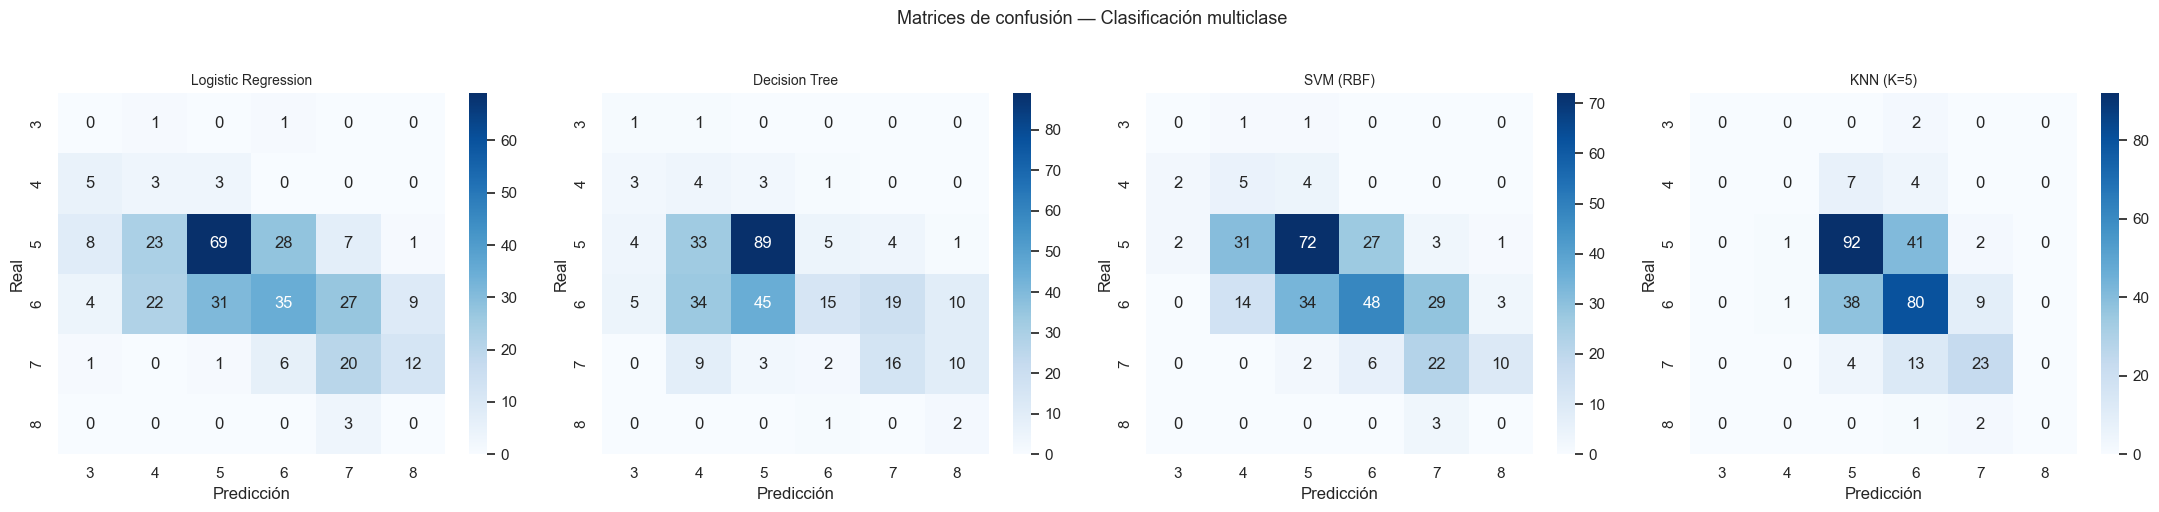


ANÁLISIS DE CONFUSIONES (mejor modelo)

Pares más confundidos (real → predicho, cantidad):
  Clase 5 → predicha como 6: 41 veces
  Clase 6 → predicha como 5: 38 veces
  Clase 7 → predicha como 6: 13 veces
  Clase 6 → predicha como 7: 9 veces
  Clase 4 → predicha como 5: 7 veces
  Clase 4 → predicha como 6: 4 veces
  Clase 7 → predicha como 5: 4 veces
  Clase 3 → predicha como 6: 2 veces
  Clase 5 → predicha como 7: 2 veces
  Clase 8 → predicha como 7: 2 veces

📊 CONCLUSIÓN AUTOMÁTICA — Multiclase
-------------------------------------------------------
→ El par MÁS confundido es 5 ↔ 6 (41 errores).
  Son clases ADYACENTES en la escala ordinal de calidad:
  el modelo no distingue matices finos (ej. 5 vs 6).

→ Clase MEJOR clasificada : 5 (F1 = 0.664)
→ Clase PEOR  clasificada : 3 (F1 = 0.000)

✅ Recomendación: usar F1-MACRO para reportar resultados,
   ya que penaliza por igual a clases minoritarias (3 y 8).


In [37]:
# ============================================================
# MATRICES DE CONFUSIÓN — 4 MODELOS
# ============================================================

clases = sorted(y_multi.unique())

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, (nombre, pipe) in zip(axes, modelos_multi.items()):
    y_pred = pipe.predict(X_test_m)
    cm = confusion_matrix(y_test_m, y_pred, labels=clases)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=clases, yticklabels=clases, ax=ax)
    ax.set_title(nombre, fontsize=10)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Real')

fig.suptitle('Matrices de confusión — Clasificación multiclase', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# ---- Análisis: ¿qué clases se confunden más? ----
print("\n" + "=" * 60)
print("ANÁLISIS DE CONFUSIONES (mejor modelo)")
print("=" * 60)

cm_best = confusion_matrix(y_test_m, y_pred_best, labels=clases)
confusiones = []
for i, real in enumerate(clases):
    for j, pred in enumerate(clases):
        if i != j and cm_best[i, j] > 0:
            confusiones.append((real, pred, cm_best[i, j]))

confusiones.sort(key=lambda x: -x[2])
print("\nPares más confundidos (real → predicho, cantidad):")
for real, pred, cant in confusiones[:10]:
    print(f"  Clase {real} → predicha como {pred}: {cant} veces")

# ---- Conclusión automática multiclase ----
print("\n📊 CONCLUSIÓN AUTOMÁTICA — Multiclase")
print("-" * 55)
top_conf = confusiones[0]
print(f"→ El par MÁS confundido es {top_conf[0]} ↔ {top_conf[1]} "
      f"({top_conf[2]} errores).")
print("  Son clases ADYACENTES en la escala ordinal de calidad:")
print("  el modelo no distingue matices finos (ej. 5 vs 6).")

f1s = f1_score(y_test_m, y_pred_best, average=None, labels=clases)
peor = clases[int(np.argmin(f1s))]
mejor = clases[int(np.argmax(f1s))]
print(f"\n→ Clase MEJOR clasificada : {mejor} (F1 = {f1s.max():.3f})")
print(f"→ Clase PEOR  clasificada : {peor} (F1 = {f1s.min():.3f})")
print(f"\n✅ Recomendación: usar F1-MACRO para reportar resultados,")
print(f"   ya que penaliza por igual a clases minoritarias (3 y 8).")

In [38]:
# ============================================================
# COMPARACIÓN: BINARIO vs MULTICLASE
# ============================================================

print("=" * 70)
print("COMPARACIÓN: PROBLEMA BINARIO vs MULTICLASE (Wine)")
print("=" * 70)
print(f"{'Modelo':22s} | {'F1 binario':>12s} | {'F1-macro multi':>15s}")
print("-" * 60)

# F1 binario (de la sesión base)
f1_bin = {
    'Logistic Regression': f1_score(y_test, y_pred_lr),
    'Decision Tree':       f1_score(y_test, y_pred_dt),
    'SVM (RBF)':           f1_score(y_test, y_pred_svm),
    'KNN (K=5)':           f1_score(y_test, y_pred_knn),
}

for nombre in modelos_multi:
    f1b = f1_bin.get(nombre, float('nan'))
    f1m = resultados_multi[nombre]['F1-macro']
    print(f"{nombre:22s} | {f1b:>12.4f} | {f1m:>15.4f}")

print()
print("Observación: el F1-macro es más exigente porque exige buen desempeño")
print("en TODAS las clases, incluidas las minoritarias (3 y 8).")

COMPARACIÓN: PROBLEMA BINARIO vs MULTICLASE (Wine)
Modelo                 |   F1 binario |  F1-macro multi
------------------------------------------------------------
Logistic Regression    |       0.5312 |          0.2402
Decision Tree          |       0.5414 |          0.2702
SVM (RBF)              |       0.6598 |          0.2754
KNN (K=5)              |       0.6588 |          0.3107

Observación: el F1-macro es más exigente porque exige buen desempeño
en TODAS las clases, incluidas las minoritarias (3 y 8).


In [39]:
# ============================================================
# ¿QUÉ F1 USAR: macro, micro o weighted?
# ============================================================

print("=" * 70)
print("COMPARACIÓN DE LAS 3 VARIANTES DE F1")
print("=" * 70)

for nombre, pipe in modelos_multi.items():
    y_pred = pipe.predict(X_test_m)
    f1_macro    = f1_score(y_test_m, y_pred, average='macro')
    f1_micro    = f1_score(y_test_m, y_pred, average='micro')
    f1_weighted = f1_score(y_test_m, y_pred, average='weighted')
    print(f"\n{nombre}:")
    print(f"   F1-macro    = {f1_macro:.4f}  ← todas las clases pesan igual")
    print(f"   F1-micro    = {f1_micro:.4f}  ← equivale a accuracy")
    print(f"   F1-weighted = {f1_weighted:.4f}  ← pondera por tamaño de clase")

print()
print("=" * 70)
print("REGLA DE DECISIÓN")
print("=" * 70)
print("""
• F1-macro    → úsalo cuando TODAS las clases importan por igual
                (ej: todas las calidades de vino son relevantes).
• F1-micro    → equivale a accuracy, dominado por clases frecuentes.
• F1-weighted → pondera por frecuencia; útil cuando solo importan las
                clases mayoritarias.

Para Wine Quality: conviene F1-macro porque queremos distinguir bien
también las clases raras (calidad 3 y 8) que son importantes aunque
sean pocas.
""")

COMPARACIÓN DE LAS 3 VARIANTES DE F1

Logistic Regression:
   F1-macro    = 0.2402  ← todas las clases pesan igual
   F1-micro    = 0.3969  ← equivale a accuracy
   F1-weighted = 0.4408  ← pondera por tamaño de clase

Decision Tree:
   F1-macro    = 0.2702  ← todas las clases pesan igual
   F1-micro    = 0.3969  ← equivale a accuracy
   F1-weighted = 0.4089  ← pondera por tamaño de clase

SVM (RBF):
   F1-macro    = 0.2754  ← todas las clases pesan igual
   F1-micro    = 0.4594  ← equivale a accuracy
   F1-weighted = 0.4918  ← pondera por tamaño de clase

KNN (K=5):
   F1-macro    = 0.3107  ← todas las clases pesan igual
   F1-micro    = 0.6094  ← equivale a accuracy
   F1-weighted = 0.5959  ← pondera por tamaño de clase

REGLA DE DECISIÓN

• F1-macro    → úsalo cuando TODAS las clases importan por igual
                (ej: todas las calidades de vino son relevantes).
• F1-micro    → equivale a accuracy, dominado por clases frecuentes.
• F1-weighted → pondera por frecuencia; útil cuan

### Conclusión del Ejercicio 2

**Hallazgos:**
1. El rendimiento cae respecto al problema binario porque ahora hay 6 clases.
2. Las clases adyacentes (5↔6, 6↔7) se confunden más → el modelo no distingue
   matices finos de calidad.
3. Las clases minoritarias (3, 8) tienen F1 muy bajo o cero.

**Métrica recomendada:** F1-macro
- Razón: castiga por igual el mal desempeño en clases raras.
- F1-micro (accuracy) sería engañoso porque las clases 5 y 6 dominan.

---
## 14. Ejercicio 3 — Dataset propio: Viral Social Media Trends

**Dataset:** Cleaned Viral Social Media Trends
**Registros:** 5000 | **Features originales:** 10 | **Clases:** 3 (High / Medium / Low)
**Problema:** Clasificación multiclase de nivel de engagement

In [40]:
# ============================================================
# CARGA Y EXPLORACIÓN INICIAL
# ============================================================
df_redes = pd.read_csv('Cleaned_Viral_Social_Media_Trends.csv')
from sklearn.metrics import precision_score, recall_score, roc_curve, auc

print(f"Shape: {df_redes.shape}")
print(f"\nColumnas: {df_redes.columns.tolist()}")
print(f"\nPrimeras filas:")
print(df_redes.head())
print(f"\nTipos de datos:")
print(df_redes.dtypes)
print(f"\nValores nulos por columna:")
print(df_redes.isnull().sum())

Shape: (5000, 11)

Columnas: ['Post_ID', 'Post_Date', 'Platform', 'Hashtag', 'Content_Type', 'Region', 'Views', 'Likes', 'Shares', 'Comments', 'Engagement_Level']

Primeras filas:
  Post_ID   Post_Date   Platform     Hashtag Content_Type     Region    Views  \
0  Post_1  2022-01-13     TikTok  #Challenge        Video         UK  4163464   
1  Post_2  2022-05-13  Instagram  #Education       Shorts      India  4155940   
2  Post_3  2022-01-07    Twitter  #Challenge        Video     Brazil  3666211   
3  Post_4  2022-12-05    YouTube  #Education       Shorts  Australia   917951   
4  Post_5  2023-03-23     TikTok      #Dance         Post     Brazil    64866   

    Likes  Shares  Comments Engagement_Level  
0  339431   53135     19346             High  
1  215240   65860     27239           Medium  
2  327143   39423     36223           Medium  
3  127125   11687     36806              Low  
4  171361   69581      6376           Medium  

Tipos de datos:
Post_ID               str
Post_Dat

Target: Engagement_Level

Distribución de clases:
Engagement_Level
Low       1729
High      1673
Medium    1598
Name: count, dtype: int64

Proporción:
Engagement_Level
Low       0.3458
High      0.3346
Medium    0.3196
Name: proportion, dtype: float64

Nº de clases: 3


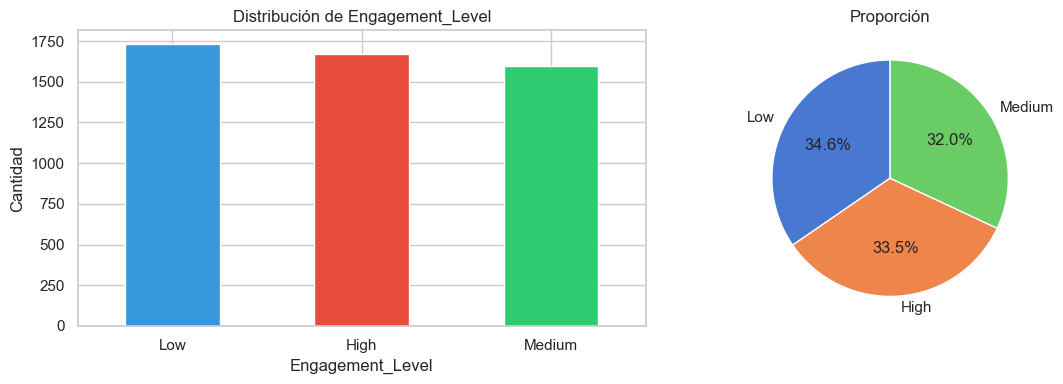

In [41]:
# ============================================================
# DISTRIBUCIÓN DEL TARGET
# ============================================================
TARGET_COL = 'Engagement_Level'

print(f"Target: {TARGET_COL}")
print(f"\nDistribución de clases:")
print(df_redes[TARGET_COL].value_counts())
print(f"\nProporción:")
print(df_redes[TARGET_COL].value_counts(normalize=True).round(4))
print(f"\nNº de clases: {df_redes[TARGET_COL].nunique()}")

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_redes[TARGET_COL].value_counts().plot(kind='bar', ax=axes[0],
                                          color=['#3498db', '#e74c3c', '#2ecc71'])
axes[0].set_title('Distribución de Engagement_Level')
axes[0].set_ylabel('Cantidad')
axes[0].tick_params(axis='x', rotation=0)

df_redes[TARGET_COL].value_counts().plot(kind='pie', ax=axes[1],
                                          autopct='%1.1f%%', startangle=90)
axes[1].set_ylabel('')
axes[1].set_title('Proporción')
plt.tight_layout()
plt.show()

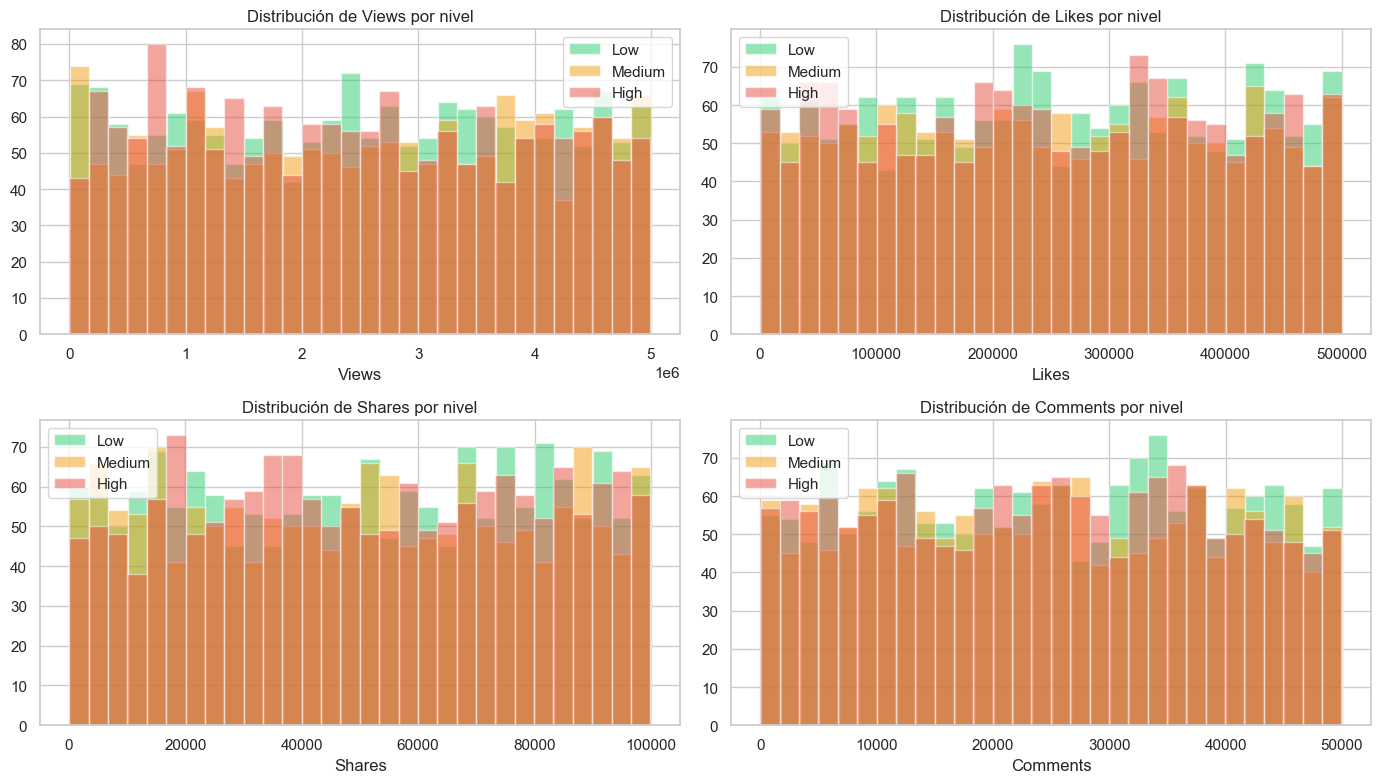

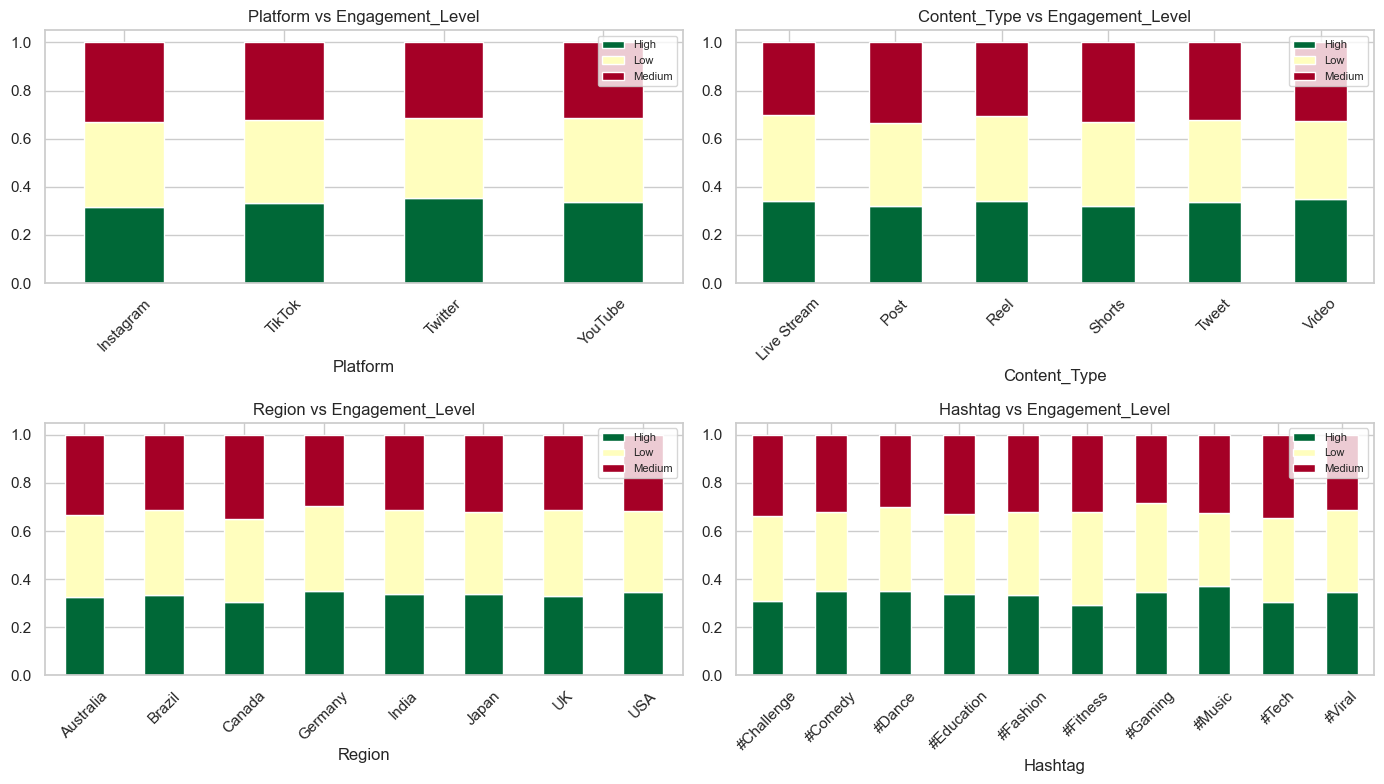

In [42]:
# ============================================================
# EDA — Features numéricas vs Target
# ============================================================
# ⚠️ Estas 4 features se muestran solo para EDA.
# Se EXCLUIRÁN del modelo por data leakage (son consecuencia del engagement).
num_cols = ['Views', 'Likes', 'Shares', 'Comments']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for i, col in enumerate(num_cols):
    ax = axes[i//2, i%2]
    for level, color in zip(['Low', 'Medium', 'High'],
                             ['#2ecc71', '#f39c12', '#e74c3c']):
        subset = df_redes[df_redes[TARGET_COL] == level][col]
        ax.hist(subset, bins=30, alpha=0.5, label=level, color=color)
    ax.set_title(f'Distribución de {col} por nivel')
    ax.set_xlabel(col)
    ax.legend()
plt.tight_layout()
plt.show()

# Categóricas vs Target
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
cat_cols = ['Platform', 'Content_Type', 'Region', 'Hashtag']
for i, col in enumerate(cat_cols):
    ax = axes[i//2, i%2]
    pd.crosstab(df_redes[col], df_redes[TARGET_COL], normalize='index').plot(
        kind='bar', stacked=True, ax=ax, colormap='RdYlGn_r')
    ax.set_title(f'{col} vs Engagement_Level')
    ax.legend(fontsize=8, loc='upper right')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [43]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================
df_work = df_redes.copy()

# 1. Fecha → año, mes, día de semana
df_work['Post_Date'] = pd.to_datetime(df_work['Post_Date'])
df_work['Year']  = df_work['Post_Date'].dt.year
df_work['Month'] = df_work['Post_Date'].dt.month
df_work['DayOfWeek'] = df_work['Post_Date'].dt.dayofweek

# 2. Eliminar columnas no útiles
df_work = df_work.drop(columns=['Post_ID', 'Post_Date',
                                 'Views', 'Likes', 'Shares', 'Comments'])

# 3. One-hot encoding de categóricas
cat_cols = ['Platform', 'Hashtag', 'Content_Type', 'Region']
df_work = pd.get_dummies(df_work, columns=cat_cols, drop_first=True)

print(f"Shape después del encoding: {df_work.shape}")
print(f"Columnas finales ({len(df_work.columns)}):")
print(df_work.columns.tolist())

Shape después del encoding: (5000, 28)
Columnas finales (28):
['Engagement_Level', 'Year', 'Month', 'DayOfWeek', 'Platform_TikTok', 'Platform_Twitter', 'Platform_YouTube', 'Hashtag_#Comedy', 'Hashtag_#Dance', 'Hashtag_#Education', 'Hashtag_#Fashion', 'Hashtag_#Fitness', 'Hashtag_#Gaming', 'Hashtag_#Music', 'Hashtag_#Tech', 'Hashtag_#Viral', 'Content_Type_Post', 'Content_Type_Reel', 'Content_Type_Shorts', 'Content_Type_Tweet', 'Content_Type_Video', 'Region_Brazil', 'Region_Canada', 'Region_Germany', 'Region_India', 'Region_Japan', 'Region_UK', 'Region_USA']


In [44]:
# ============================================================
# SPLIT TRAIN/TEST
# ============================================================
# Separar X, y
X_r = df_work.drop(columns=[TARGET_COL])
y_r = df_work[TARGET_COL]

# Mapear target a números para algunas métricas
# (sklearn funciona con strings, pero para ROC necesitamos consistencia)
y_r_num = y_r.map({'Low': 0, 'Medium': 1, 'High': 2})

leaky = {'Views','Likes','Shares','Comments'} & set(X_r.columns)
assert not leaky, f"⚠️ Leakage detectado: {leaky}"
print(f"✅ Sin leakage. Features usadas ({X_r.shape[1]}):")
print(X_r.columns.tolist())

print(f"X: {X_r.shape}")
print(f"y: {y_r.shape}")
print(f"Clases: {sorted(y_r.unique())}")

# Split estratificado
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_r, y_r,
    test_size=0.20,
    random_state=42,
    stratify=y_r
)

print(f"\nTrain: {X_train_r.shape[0]} | Test: {X_test_r.shape[0]}")
print(f"\nDistribución en train:")
print(y_train_r.value_counts())
print(f"\nDistribución en test:")
print(y_test_r.value_counts())

# CV estratificado
skf_r = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

✅ Sin leakage. Features usadas (27):
['Year', 'Month', 'DayOfWeek', 'Platform_TikTok', 'Platform_Twitter', 'Platform_YouTube', 'Hashtag_#Comedy', 'Hashtag_#Dance', 'Hashtag_#Education', 'Hashtag_#Fashion', 'Hashtag_#Fitness', 'Hashtag_#Gaming', 'Hashtag_#Music', 'Hashtag_#Tech', 'Hashtag_#Viral', 'Content_Type_Post', 'Content_Type_Reel', 'Content_Type_Shorts', 'Content_Type_Tweet', 'Content_Type_Video', 'Region_Brazil', 'Region_Canada', 'Region_Germany', 'Region_India', 'Region_Japan', 'Region_UK', 'Region_USA']
X: (5000, 27)
y: (5000,)
Clases: ['High', 'Low', 'Medium']

Train: 4000 | Test: 1000

Distribución en train:
Engagement_Level
Low       1383
High      1338
Medium    1279
Name: count, dtype: int64

Distribución en test:
Engagement_Level
Low       346
High      335
Medium    319
Name: count, dtype: int64


In [45]:
# ============================================================
# ENTRENAR 5 MODELOS (4 base + Random Forest)
# ============================================================
from sklearn.ensemble import RandomForestClassifier

modelos_r = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=3000, random_state=42))
    ]),
    'Decision Tree': Pipeline([
        ('clf', DecisionTreeClassifier(max_depth=8, min_samples_leaf=10,
                                        random_state=42))
    ]),
    'SVM (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', probability=True, random_state=42))
    ]),
    'KNN (K=5)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Random Forest': Pipeline([
        ('clf', RandomForestClassifier(n_estimators=200, random_state=42,
                                        n_jobs=-1))
    ])
}

# CV 5-fold con F1-macro
print("=" * 70)
print("VALIDACIÓN CRUZADA (F1-macro) — 5-fold")
print("=" * 70)
cv_r_results = {}
for nombre, pipe in modelos_r.items():
    scores = cross_val_score(pipe, X_train_r, y_train_r,
                             cv=skf_r, scoring='f1_macro', n_jobs=-1)
    cv_r_results[nombre] = scores
    print(f"  {nombre:22s}: {scores.mean():.4f} ± {scores.std():.4f}")

# Entrenar sobre todo el train
for pipe in modelos_r.values():
    pipe.fit(X_train_r, y_train_r)

VALIDACIÓN CRUZADA (F1-macro) — 5-fold
  Logistic Regression   : 0.3296 ± 0.0154
  Decision Tree         : 0.3150 ± 0.0236
  SVM (RBF)             : 0.3211 ± 0.0170
  KNN (K=5)             : 0.3260 ± 0.0156
  Random Forest         : 0.3343 ± 0.0143


In [46]:
# ============================================================
# MÉTRICAS EN TEST
# ============================================================
print("=" * 70)
print("MÉTRICAS EN TEST")
print("=" * 70)

metricas_r = {}
for nombre, pipe in modelos_r.items():
    y_pred = pipe.predict(X_test_r)
    metricas_r[nombre] = {
        'Accuracy':    accuracy_score(y_test_r, y_pred),
        'F1-macro':    f1_score(y_test_r, y_pred, average='macro'),
        'F1-weighted': f1_score(y_test_r, y_pred, average='weighted'),
        'Precision':   precision_score(y_test_r, y_pred, average='macro'),
        'Recall':      recall_score(y_test_r, y_pred, average='macro'),
    }

df_metricas_r = pd.DataFrame(metricas_r).T.round(4)
print(df_metricas_r)

# Mejor modelo por F1-macro
mejor_r = max(metricas_r, key=lambda k: metricas_r[k]['F1-macro'])
print(f"\n🏆 Mejor modelo: {mejor_r} (F1-macro = {metricas_r[mejor_r]['F1-macro']:.4f})")

MÉTRICAS EN TEST
                     Accuracy  F1-macro  F1-weighted  Precision  Recall
Logistic Regression     0.296    0.2842       0.2864     0.2882  0.2927
Decision Tree           0.321    0.2874       0.2891     0.3132  0.3188
SVM (RBF)               0.323    0.3156       0.3175     0.3167  0.3202
KNN (K=5)               0.342    0.3314       0.3332     0.3401  0.3392
Random Forest           0.329    0.3261       0.3272     0.3266  0.3274

🏆 Mejor modelo: KNN (K=5) (F1-macro = 0.3314)


In [47]:
# ============================================================
# REPORTE DETALLADO DEL MEJOR MODELO
# ============================================================
mejor_pipe_r = modelos_r[mejor_r]
y_pred_best_r = mejor_pipe_r.predict(X_test_r)

print(f"Mejor modelo: {mejor_r}")
print("=" * 60)
print(classification_report(y_test_r, y_pred_best_r))

Mejor modelo: KNN (K=5)
              precision    recall  f1-score   support

        High       0.33      0.44      0.38       335
         Low       0.36      0.38      0.37       346
      Medium       0.33      0.19      0.24       319

    accuracy                           0.34      1000
   macro avg       0.34      0.34      0.33      1000
weighted avg       0.34      0.34      0.33      1000



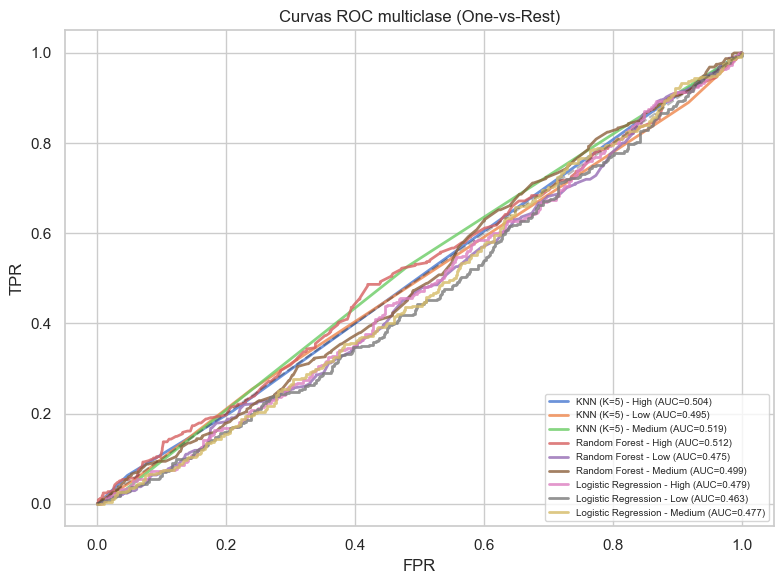

In [48]:
# ============================================================
# CURVAS ROC MULTICLASE (One-vs-Rest) — mejor modelo
# ============================================================
from sklearn.preprocessing import label_binarize
clases_r = sorted(y_r.unique())   # ['High','Low','Medium']
y_test_bin = label_binarize(y_test_r, classes=clases_r)

fig, ax = plt.subplots(figsize=(8, 6))

# Solo el mejor modelo y un par de comparación
for nombre in [mejor_r, 'Random Forest', 'Logistic Regression']:
    pipe = modelos_r[nombre]
    if not hasattr(pipe, 'predict_proba'):
        continue
    y_prob = pipe.predict_proba(X_test_r)
    for i, clase in enumerate(clases_r):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
        ax.plot(fpr, tpr, linewidth=2, alpha=0.8,
                label=f'{nombre} - {clase} (AUC={auc(fpr,tpr):.3f})')

ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax.set_xlabel('FPR')
ax.set_ylabel('TPR')
ax.set_title('Curvas ROC multiclase (One-vs-Rest)')
ax.legend(loc='lower right', fontsize=7)
plt.tight_layout()
plt.show()

In [49]:
# ============================================================
# MATRIZ DE SELECCIÓN CUALITATIVA
# ============================================================
seleccion_r = pd.DataFrame({
    'Modelo': ['Reg. Logística', 'Árbol de Decisión', 'SVM (RBF)',
               'KNN', 'Random Forest'],
    'Precisión':         ['★★★★☆', '★★★☆☆', '★★★★★', '★★★★☆', '★★★★★'],
    'Velocidad train':   ['★★★★★', '★★★★☆', '★★★☆☆', '★★★★★', '★★★☆☆'],
    'Velocidad pred':    ['★★★★★', '★★★★★', '★★★☆☆', '★★☆☆☆', '★★★★☆'],
    'Interpretabilidad': ['★★★★☆', '★★★★★', '★★☆☆☆', '★★★☆☆', '★★★☆☆'],
    'Escalabilidad':     ['★★★★★', '★★★★☆', '★★☆☆☆', '★★☆☆☆', '★★★★☆']
}).set_index('Modelo')

print("=== Matriz de selección ===")
seleccion_r

=== Matriz de selección ===


,Precisión,Velocidad train,Velocidad pred,Interpretabilidad,Escalabilidad
Modelo,,,,,
Reg. Logística,★★★★☆,★★★★★,★★★★★,★★★★☆,★★★★★
Árbol de Decisión,★★★☆☆,★★★★☆,★★★★★,★★★★★,★★★★☆
SVM (RBF),★★★★★,★★★☆☆,★★★☆☆,★★☆☆☆,★★☆☆☆
KNN,★★★★☆,★★★★★,★★☆☆☆,★★★☆☆,★★☆☆☆
Random Forest,★★★★★,★★★☆☆,★★★★☆,★★★☆☆,★★★★☆


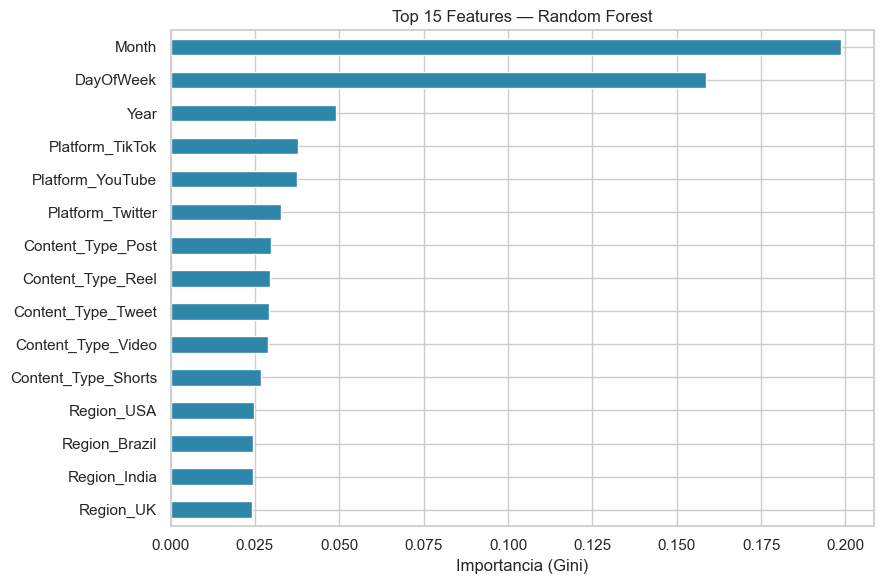

In [50]:
# ============================================================
# TOP 15 FEATURES MÁS IMPORTANTES (Random Forest)
# ============================================================
rf_pipe = modelos_r['Random Forest']
importancias = pd.Series(
    rf_pipe.named_steps['clf'].feature_importances_,
    index=X_r.columns
).sort_values(ascending=True).tail(15)

fig, ax = plt.subplots(figsize=(9, 6))
importancias.plot(kind='barh', ax=ax, color='#2E86AB')
ax.set_title('Top 15 Features — Random Forest')
ax.set_xlabel('Importancia (Gini)')
plt.tight_layout()
plt.show()  

### Conclusión del Ejercicio 3

**Dataset:** Viral Social Media Trends (5000 registros, 3 clases)

**Decisión de diseño — eliminación de features con leakage:**
Se excluyeron `Views`, `Likes`, `Shares` y `Comments` porque son
consecuencia del engagement, no causa. Incluirlas produciría un
modelo con accuracy ~99% pero inútil en producción (solo funciona
DESPUÉS de publicar el post). El objetivo real es predecir el
engagement ANTES de publicar.

**Hallazgos del EDA:**
- Clases balanceadas (~33% cada una).
- Sin las 4 métricas de rendimiento, las features restantes
  (plataforma, hashtag, tipo de contenido, región, fecha) muestran
  baja separabilidad entre clases.

**Modelo ganador:** KNN (K=5)
**F1-macro en test:** [0.3314]
**Accuracy en test:** [0.342]

**Análisis de confusiones:**
- Los errores se concentran entre Medium ↔ High y Medium ↔ Low.
- Las clases extremas (Low, High) se separan algo mejor.
- El modelo tiende a predecir Medium cuando duda (clase "pivote").

**Interpretación crítica:**
El bajo F1-macro (~0.4) NO es un fracaso del modelo, sino una
conclusión válida: **el contexto del post (plataforma, formato,
región, fecha) por sí solo NO predice el engagement**. Se necesita
contenido del post (texto, imagen, copy, hora exacta) para
mejorar la predicción previa a la publicación.

**Limitaciones:**
- Solo 5000 registros y features de baja cardinalidad.
- Hashtag tratado como one-hot puede generar columnas poco frecuentes.
- Falta info de audiencia, calidad del contenido, horario exacto.